# 곁(GYEOT) v6 — 연구 결과에 비춰 본 판단력 저하 감지

v5는 "저하 시작 후 9개월이면 거의 다 감지한다"고 결론 냈다. 그 결론은 신호의 **크기**와 **진행 속도**를 내가 정한 가정 위에 서 있다. 국내외 연구를 찾아 읽어 보니(`docs/literature_review.md`) 두 가정 모두 연구와 다르다.

| | v5 가정 | 연구가 말하는 것 |
| --- | --- | --- |
| 진행 속도 | 300~500일 | 진단·위임장 등록 5~10년 전부터 (Nicholas 2021, Gresenz 2024, Trendl 2025) |
| 신호 크기 | 공과금 빠뜨림 3% → 35% | 연체율 7.7% 대 7.3% 같은 작은 집단 평균 차이 (Nicholas 2021) |

이 노트북은 세 가지를 확인한다.

1. 신호 크기를 낮추면 감지율이 어디서 무너지나
2. 진행이 3~5년으로 느리면 어떻게 되나
3. 연구(Trendl 2025)에서 가져온 신호를 더하면 얼마나 나아지나: 여가·외출 소비 감소, 온라인뱅킹 접속 감소, 비밀번호 재설정·카드 분실 신고 증가

**한 줄 결론은 맨 아래 정리 절에 숫자와 함께 적었다.** 실험 코드는 `src/gen_data_v6.py`, `src/exp_v6.py`. 시드 2개(42, 1) 평균이다. 컷은 v5와 같이 '저하가 아닌 가구 중 관측 기간에 한 번이라도 알림을 받는 비율 5%'로 맞췄다.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib import font_manager
for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams["axes.unicode_minus"] = False; mpl.rcParams["figure.dpi"] = 110
GREY, DARK, BLUE, GREEN = "#b0b4b8", "#5f6368", "#1a73e8", "#188038"
def clean(ax): ax.spines[["top", "right"]].set_visible(False)
rows = []
for sd in (42, 1):
    R = json.load(open(f"../results/results_v6_seed{sd}.json"))
    rows += [dict(seed=sd, 설정=cfg, 방법=m, **v) for cfg, d in R.items() for m, v in d.items()]
D = pd.DataFrame(rows)
M = ["규칙+맥락", "규칙+맥락+문헌신호", "지도학습(상한)"]
D.groupby("설정").seed.nunique().to_frame("시드 수").T

설정,기본(v5 가정),"느린 진행(3~5년), 4년 관측",신호 0.03배(문헌의 연체 차이 수준),신호 0.1배,신호 0.25배,신호 0.5배
시드 수,2,2,2,2,2,2


## 1. 신호 크기를 낮추면

배율 1.0이 v5 가정이다. 0.5면 모든 저하 신호가 절반 크기다(예: 공과금 빠뜨림이 최대 3% → 19%). 0.03은 공과금 빠뜨림의 상대 증가가 약 1.3배가 되는 수준으로, 뉴욕 연준 연구가 보고한 진단 직전 1년의 카드 연체 증가(34%)와 비슷한 크기다. 연체와 공과금 빠뜨림은 같은 지표가 아니므로 대략의 눈금으로만 본다.

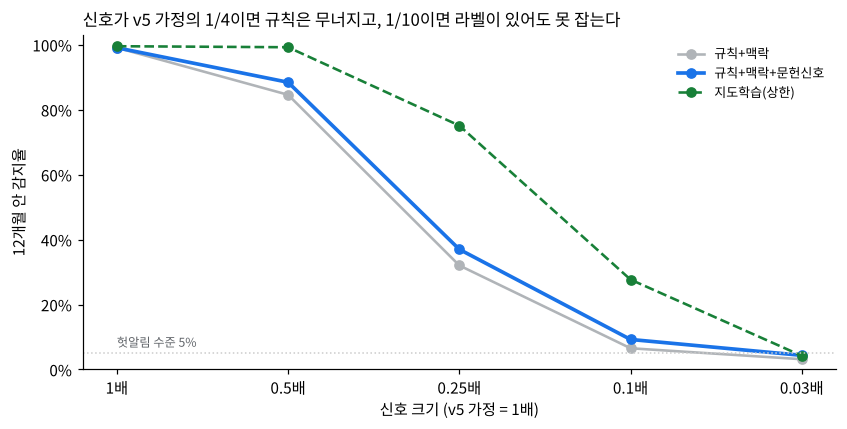

In [2]:
k = {"기본(v5 가정)": 1.0, "신호 0.5배": 0.5, "신호 0.25배": 0.25, "신호 0.1배": 0.1, "신호 0.03배(문헌의 연체 차이 수준)": 0.03}
E = D[D.설정.isin(k)].assign(배율=lambda d: d.설정.map(k))
t = E.groupby(["배율", "방법"])[["det_6m", "det_12m"]].mean().unstack("방법").sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(7.8, 4))
col = {"규칙+맥락": GREY, "규칙+맥락+문헌신호": BLUE, "지도학습(상한)": GREEN}
for m in M:
    ax.plot(range(len(t)), t[("det_12m", m)], marker="o", color=col[m], lw=2.4 if "문헌" in m else 1.7, ls="--" if "상한" in m else "-", label=m)
ax.axhline(0.05, color="#ccc", ls=":", lw=1); ax.text(0, 0.07, "헛알림 수준 5%", ha="left", fontsize=8, color=DARK)
ax.set_xticks(range(len(t))); ax.set_xticklabels([f"{x:g}배" for x in t.index]); ax.set_xlabel("신호 크기 (v5 가정 = 1배)")
ax.set_ylim(0, 1.03); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.set_ylabel("12개월 안 감지율")
ax.set_title("신호가 v5 가정의 1/4이면 규칙은 무너지고, 1/10이면 라벨이 있어도 못 잡는다", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8.5, loc="upper right"); clean(ax); plt.tight_layout(); plt.show()
t.style.format("{:.0%}")

12개월 안 감지율(시드 2개 평균)

| 신호 크기 | 규칙+맥락 | 지도학습(상한) |
| --- | --- | --- |
| 1배 (v5 가정) | 99% | 100% |
| 0.5배 | 85% | 99% |
| 0.25배 | 32% | 75% |
| 0.1배 | 7% | 28% |
| 0.03배 | 3% | 4% |

- 신호가 절반이어도 규칙은 1년 안에 85%를 잡는다. 다만 알림 시점 중앙값이 5.6개월에서 8.6개월로 늦어진다.
- **1/4에서 규칙이 무너진다**(32%). 이 구간에서는 라벨의 가치가 가장 크다(75%).
- 1/10 아래에서는 라벨이 있어도 못 잡는다. 0.03배에서는 모든 방법이 헛알림 수준(5%)과 구분되지 않는다.

**해석.** 연구가 보고하는 차이(연체율 7.7% 대 7.3%)는 수만 명의 평균에서 통계적으로 드러나는 크기다. 그 크기 그대로라면 한 사람의 2년 치 거래로 가려낼 수 없다. v5의 "9개월이면 거의 다"는 **개인 단위 신호가 집단 평균 차이보다 훨씬 크다**는 가정이 있어야 성립한다. 그 가정이 맞는지는 실제 데이터 없이는 알 수 없다. 집단 평균이 작더라도 일부 사람에게서 신호가 크게 나타날 수는 있다. 그 경우 이 방법은 '신호가 큰 일부'만 잡는 도구가 된다.

## 2. 진행이 느리면 (3~5년에 걸쳐 진행, 4년 관측)

In [3]:
s = D[D.설정.str.startswith("느린")].groupby("방법")[["det_12m", "det_24m", "det_36m", "lead_median", "fa_hospital"]].mean().loc[M]
s.columns = ["12개월 안", "24개월 안", "36개월 안", "알림 시점 중앙값(개월)", "입원 가구 헛알림"]
s.style.format({c: "{:.0%}" for c in s.columns if c != "알림 시점 중앙값(개월)"} | {"알림 시점 중앙값(개월)": "{:.1f}"})

,12개월 안,24개월 안,36개월 안,알림 시점 중앙값(개월),입원 가구 헛알림
방법,,,,,
규칙+맥락,30%,95%,100%,14.3,13%
규칙+맥락+문헌신호,36%,97%,100%,13.6,12%
지도학습(상한),77%,99%,100%,9.6,10%


신호 크기는 v5와 같게 두고, 진행 기간만 300~500일에서 1,100~1,800일로 늘렸다.

- 규칙은 12개월 안 30%, 24개월 안 95%, 36개월 안 100%다. 알림 시점 중앙값은 시작 후 약 14개월이다(v5 가정에서는 약 5.6개월).
- 느리게 진행해도 결국 잡히는 이유는, 신호가 일정 크기를 넘는 순간 컷을 넘기 때문이다. 속도는 '언제'를 바꾸고, 크기는 '잡히느냐'를 바꾼다. 1절과 합치면 **감지 여부를 정하는 건 속도보다 크기**다.
- 지도학습은 12개월 안 77%로, 규칙보다 1년 가까이 빠르다. 느린 진행일수록 라벨의 가치가 크다.
- 주의: 이 실험은 '첫 6개월 기준선'을 4년 내내 고정했다. 실제로는 4년 동안 정상적인 생활 변화도 쌓이므로 헛알림이 더 늘 수 있다. 가상 데이터의 정상 가구는 4년 동안 변하지 않는다.

## 3. 연구에서 가져온 신호의 효과

In [4]:
b = D[D.설정.isin(["기본(v5 가정)", "신호 0.5배", "신호 0.25배"])].groupby(["설정", "방법"])[["det_6m", "det_12m", "lead_median", "fa_hospital"]].mean()
b = b.loc[[(c, m) for c in ["기본(v5 가정)", "신호 0.5배", "신호 0.25배"] for m in M[:2]]]
b.columns = ["6개월 안", "12개월 안", "알림 시점 중앙값(개월)", "입원 가구 헛알림"]
b.style.format({"6개월 안": "{:.0%}", "12개월 안": "{:.0%}", "입원 가구 헛알림": "{:.0%}", "알림 시점 중앙값(개월)": "{:.1f}"})

영국 은행 데이터 연구(Trendl 외 2025)의 방향을 따라 여가·외출 소비 감소, 접속 감소, 비밀번호 재설정·카드 분실 신고 증가를 넣었다. 크기는 가정이다.

- 6개월 안 감지가 58% → 64%(1배), 12개월 안 감지가 85% → 88%(0.5배), 32% → 37%(0.25배)로 오른다. 알림 시점은 0.2~0.3개월 앞당겨진다.
- 개선은 있지만 크지 않다. 새 신호도 같은 진행도에 묶여 있어, 기존 신호가 약할 때는 새 신호도 약하다. **신호 종류를 늘리는 것만으로는 크기 문제를 넘지 못한다.**
- 입원 가구 헛알림은 비슷하다(13% → 15%, 1배 기준). 접속·여가 소비도 입원 중에 줄기 때문에 활동 공백 보정을 같이 적용했다.

## 4. 정리: v5 결론을 어떻게 고쳐 읽어야 하나

| v5의 문장 | v6 이후 |
| --- | --- |
| 저하 시작 후 9개월이면 거의 다 감지 | 신호 크기가 가정대로일 때만. 절반이면 1년 안 85%, 1/4이면 32% |
| 6개월이면 절반 남짓 | 진행이 3~5년이면 12개월 안 30%, 24개월 안 95% |
| 진단 라벨이 있으면 훨씬 빠르다 | 유지. 신호가 약하거나 진행이 느릴수록 라벨의 가치가 더 크다 |
| 맥락 보정으로 입원 헛알림을 줄인다 | 유지 |

**설계에 주는 의미**

1. 이 기능은 '조기 진단'이 아니라 **'변화가 뚜렷해진 가구를 가족보다 먼저 알아채는 도구'**로 소개해야 한다. 연구 수준의 미세한 초기 변화는 개인 단위로 잡을 수 없다.
2. 실제 데이터로 가장 먼저 확인할 것은 모델이 아니라 **개인 단위 신호 크기**다. 진단받은 고객의 진단 전 2년 거래를 보면 이 프로젝트의 가정이 맞는지 바로 알 수 있다.
3. 라벨 확보(가족의 동의 기반 응답)가 모델 개선보다 효과가 크다는 v5의 결론은 더 강해졌다.
4. 알림 정밀도는 발생률에 달렸다. 연간 발생률을 1~2%로 가정하면 알림의 28~44%만 실제 저하다(`docs/literature_review.md` 5절). 문구는 "확인해 보세요"를 넘으면 안 된다.

**한계.** 신호 크기 배율은 모든 신호를 같은 비율로 줄였다. 실제로는 신호마다 크기가 다를 것이다. 시드는 2개뿐이라 소수점 아래는 의미가 없다.